## Dataset inspection
- Before cleaning anything, we need to understand the actual dataset.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("../data/Dataset.csv")

# Dataset overview
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Records:")
display(df.head())

print("\nDataset Information:")
df.info()

Dataset Shape: (8790, 10)

Column Names:
['show_id', 'type', 'title', 'director', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in']

First 5 Records:


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8790 non-null   object
 1   type          8790 non-null   object
 2   title         8790 non-null   object
 3   director      8790 non-null   object
 4   country       8790 non-null   object
 5   date_added    8790 non-null   object
 6   release_year  8790 non-null   int64 
 7   rating        8790 non-null   object
 8   duration      8790 non-null   object
 9   listed_in     8790 non-null   object
dtypes: int64(1), object(9)
memory usage: 686.8+ KB


# Task 1 — Data Cleaning & Preprocessing

## Step 1.1: Data quality audit

In [2]:
# 1. Missing values
print("Missing Values:")
print(df.isnull().sum())

# 2. Duplicate records
print("\nDuplicate Rows:", df.duplicated().sum())

# 3. Duplicate show IDs
print("Duplicate Show IDs:", df["show_id"].duplicated().sum())

# 4. Unique values in categorical columns
categorical_cols = ["type", "rating"]

for col in categorical_cols:
    print(f"\n{col} unique values:")
    print(df[col].value_counts())

# 5. Check placeholder values
for col in ["director", "country", "rating"]:
    print(f"\n{col} placeholder values:")
    print(df[col].value_counts().head(10))

# 6. Check date and duration formats
print("\nDate examples:")
print(df["date_added"].head(10).tolist())

print("\nDuration examples:")
print(df["duration"].value_counts().head(10))

Missing Values:
show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64

Duplicate Rows: 0
Duplicate Show IDs: 0

type unique values:
type
Movie      6126
TV Show    2664
Name: count, dtype: int64

rating unique values:
rating
TV-MA       3205
TV-14       2157
TV-PG        861
R            799
PG-13        490
TV-Y7        333
TV-Y         306
PG           287
TV-G         220
NR            79
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64

director placeholder values:
director
Not Given                 2588
Rajiv Chilaka               20
Alastair Fothergill         18
Raúl Campos, Jan Suter      18
Marcus Raboy                16
Suhas Kadav                 16
Jay Karas                   14
Cathy Garcia-Molina         13
Jay Chapman                 12
Martin Scorsese             12
Name: count, dtype: int

## Step 1.2: Apply cleaning and transformations

In [3]:
# Create a copy of the original dataset
df_clean = df.copy()

# 1. Remove unnecessary whitespace from text columns
for col in df_clean.select_dtypes(include="object").columns:
    df_clean[col] = df_clean[col].str.strip()

# 2. Replace placeholder values with NaN
df_clean.replace(
    {"Not Given": np.nan},
    inplace=True
)

# 3. Standardize categorical columns
df_clean["type"] = df_clean["type"].str.title()
df_clean["rating"] = df_clean["rating"].str.upper()

# 4. Convert date column into datetime
df_clean["date_added"] = pd.to_datetime(
    df_clean["date_added"],
    format="%m/%d/%Y",
    errors="coerce"
)

# 5. Extract date-related features
df_clean["date_added_year"] = df_clean["date_added"].dt.year
df_clean["date_added_month"] = df_clean["date_added"].dt.month

# 6. Extract duration value and unit
df_clean["duration_value"] = pd.to_numeric(
    df_clean["duration"].str.extract(r"(\d+)")[0],
    errors="coerce"
)

df_clean["duration_unit"] = df_clean["duration"].str.extract(
    r"([A-Za-z]+)"
)[0]

# 7. Verify cleaning
print("Cleaned Dataset Shape:", df_clean.shape)

print("\nMissing Values:")
print(df_clean.isnull().sum())

print("\nData Types:")
print(df_clean.dtypes)

display(df_clean.head())

Cleaned Dataset Shape: (8790, 14)

Missing Values:
show_id                0
type                   0
title                  0
director            2588
country              287
date_added             0
release_year           0
rating                 0
duration               0
listed_in              0
date_added_year        0
date_added_month       0
duration_value         0
duration_unit          0
dtype: int64

Data Types:
show_id                     object
type                        object
title                       object
director                    object
country                     object
date_added          datetime64[ns]
release_year                 int64
rating                      object
duration                    object
listed_in                   object
date_added_year              int32
date_added_month             int32
duration_value               int64
duration_unit               object
dtype: object


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in,date_added_year,date_added_month,duration_value,duration_unit
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries,2021,9,90,min
1,s3,Tv Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",2021,9,1,Season
2,s6,Tv Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",2021,9,1,Season
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies",2021,9,91,min
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies",2021,9,125,min


In [4]:
df_clean.to_csv("../data/netflix_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


## Step 1.4 — Fix categorical standardization

In [5]:
# Correct content type labels
df_clean["type"] = df_clean["type"].replace({
    "Tv Show": "TV Show"
})

# Standardize duration units
df_clean["duration_unit"] = df_clean["duration_unit"].replace({
    "min": "Minutes",
    "Season": "Seasons"
})

# Verify
print(df_clean["type"].value_counts())
print("\nDuration units:")
print(df_clean["duration_unit"].value_counts())

# Save final cleaned dataset
df_clean.to_csv("../data/netflix_cleaned.csv", index=False)

type
Movie      6126
TV Show    2664
Name: count, dtype: int64

Duration units:
duration_unit
Minutes    6126
Seasons    2664
Name: count, dtype: int64


# Task 2 — Exploratory Data Analysis (EDA)
Now we'll answer five business questions:
1. What is the distribution of Movies vs TV Shows?
2. How has Netflix content evolved over the years?
3. Which countries contribute the most content?
4. What are the most common genres?
5. Which content ratings dominate Netflix?

## Step 2.1 — Statistical analysis

In [6]:
# Dataset overview
print("Dataset Shape:", df_clean.shape)

# Numerical statistics
display(df_clean.describe())

# Categorical statistics
display(df_clean.describe(include="object"))

# Movie vs TV Show distribution
display(df_clean["type"].value_counts())

# Percentage distribution
display(
    df_clean["type"].value_counts(normalize=True).mul(100).round(2)
)

Dataset Shape: (8790, 14)


,date_added,release_year,date_added_year,date_added_month,duration_value
count,8790,8790.000000,8790.000000,8790.000000,8790.000000
mean,2019-05-17 21:44:01.638225408,2014.183163,2018.873606,6.655859,69.934471
min,2008-01-01 00:00:00,1925.000000,2008.000000,1.000000,1.000000
25%,2018-04-06 00:00:00,2013.000000,2018.000000,4.000000,2.000000
50%,2019-07-03 00:00:00,2017.000000,2019.000000,7.000000,88.500000
75%,2020-08-19 18:00:00,2019.000000,2020.000000,10.000000,106.000000
max,2021-09-25 00:00:00,2021.000000,2021.000000,12.000000,312.000000
std,NaN,8.825466,1.573568,3.436103,50.794433


,show_id,type,title,director,country,rating,duration,listed_in,duration_unit
count,8790,8790,8790,6202,8503,8790,8790,8790,8790
unique,8790,2,8786,4527,85,14,220,513,2
top,s1,Movie,Consequences,Rajiv Chilaka,United States,TV-MA,1 Season,"Dramas, International Movies",Minutes
freq,1,6126,2,20,3240,3205,1791,362,6126


type
Movie      6126
TV Show    2664
Name: count, dtype: int64

type
Movie      69.69
TV Show    30.31
Name: proportion, dtype: float64

## Step 2.2 — Content distribution visualization

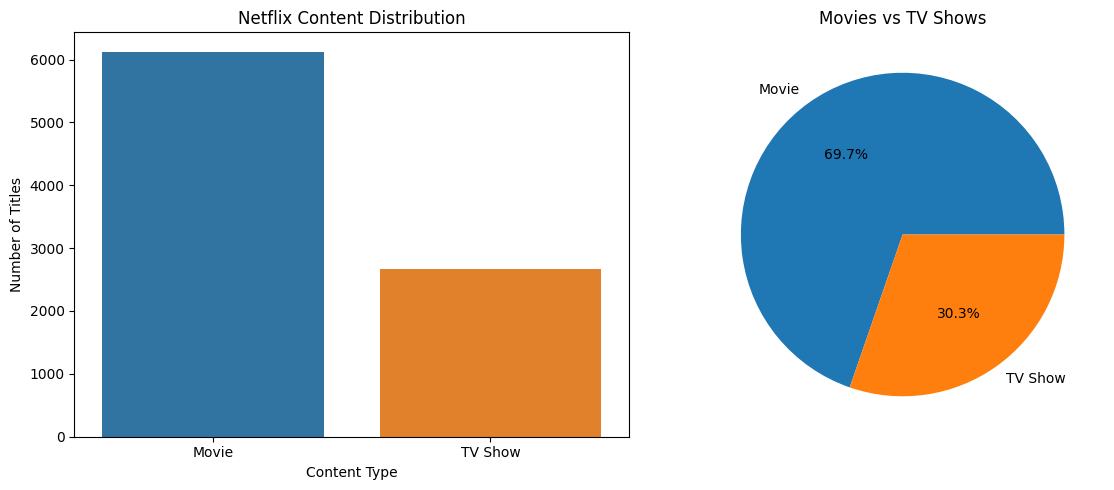

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Count plot
sns.countplot(data=df_clean, x="type", hue="type", legend=False, ax=axes[0])
axes[0].set_title("Netflix Content Distribution")
axes[0].set_xlabel("Content Type")
axes[0].set_ylabel("Number of Titles")

# Pie chart
df_clean["type"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    ax=axes[1]
)
axes[1].set_title("Movies vs TV Shows")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

## Step 2.3 — Content added over the years

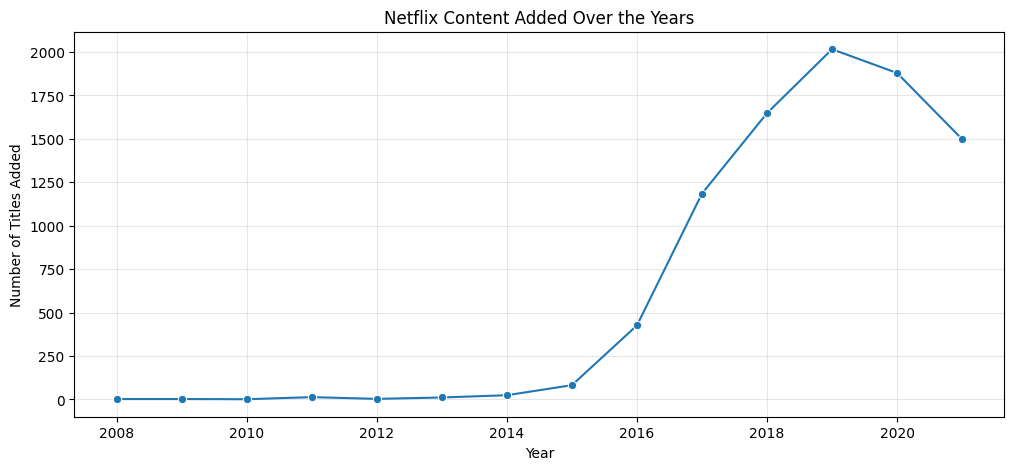

In [8]:
yearly_content = df_clean["date_added_year"].value_counts().sort_index()

plt.figure(figsize=(12, 5))
sns.lineplot(x=yearly_content.index, y=yearly_content.values, marker="o")

plt.title("Netflix Content Added Over the Years")
plt.xlabel("Year")
plt.ylabel("Number of Titles Added")
plt.grid(alpha=0.3)
plt.show()

Insight: Movies make up approximately 70% of the Netflix titles in this dataset, while TV Shows account for approximately 30%.

Dataset observations
- The dataset contains 8,790 titles and 14 columns after feature engineering.
- The average release year is approximately 2014.
- The median movie/show duration value is 88.5,( but: this combines movie minutes and TV-show seasons, so it is not a meaningful overall average duration.)
- Director is missing for 2,588 titles, and country is missing for 287 titles. These were originally represented as "Not Given" and are now correctly treated as missing.

Content added over the years
- chart suggests that Netflix content additions increased sharply from 2016, peaked around 2019, and then declined in 2020–2021.

## Step 2.4 — Top countries and popular genres

In [11]:
# Top 10 countries
top_countries = (
    df_clean["country"]
    .dropna()
    .str.split(", ")
    .explode()
    .value_counts()
    .head(10)
)

# Top 10 genres
top_genres = (
    df_clean["listed_in"]
    .dropna()
    .str.split(", ")
    .explode()
    .value_counts()
    .head(10)
)

print("Top 10 Countries:")
display(top_countries)

print("Top 10 Genres:")
display(top_genres)

Top 10 Countries:


country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Mexico             138
Name: count, dtype: int64

Top 10 Genres:


listed_in
International Movies        2752
Dramas                      2426
Comedies                    1674
International TV Shows      1349
Documentaries                869
Action & Adventure           859
TV Dramas                    762
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64

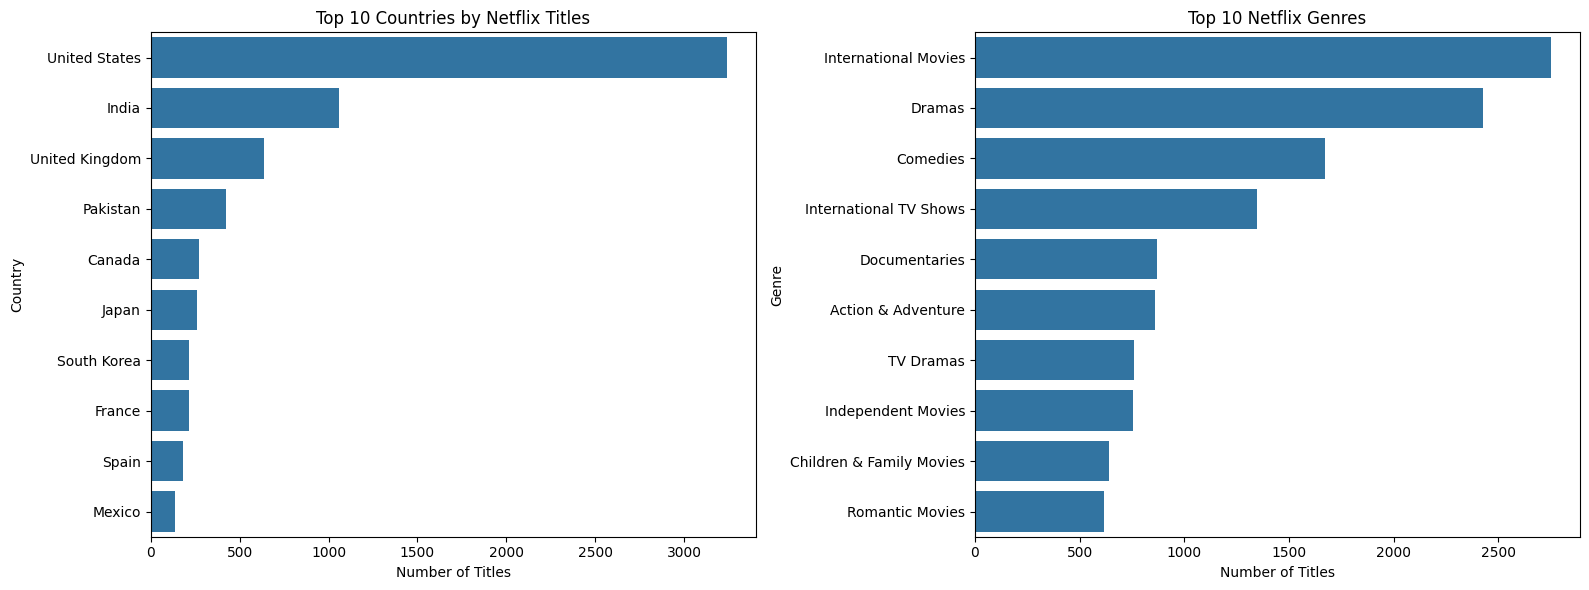

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(
    x=top_countries.values,
    y=top_countries.index,
    ax=axes[0]
)
axes[0].set_title("Top 10 Countries by Netflix Titles")
axes[0].set_xlabel("Number of Titles")
axes[0].set_ylabel("Country")

sns.barplot(
    x=top_genres.values,
    y=top_genres.index,
    ax=axes[1]
)
axes[1].set_title("Top 10 Netflix Genres")
axes[1].set_xlabel("Number of Titles")
axes[1].set_ylabel("Genre")

plt.tight_layout()
plt.show()

## EDA: Final business insights

### Country-wise content distribution
 - The United States leads with 3,240 titles.
 - India is second with 1,057 titles.
 - The United Kingdom ranks third with 638 titles.
 - The top three countries contribute a substantial share of the catalogue.

### Genre distribution
- International Movies: 2,752
- Dramas: 2,426
- Comedies: 1,674
- International TV Shows: 1,349
- Documentaries: 869

### Insight:
- International content and drama are prominent categories in this dataset. Netflix's catalogue has a strong mix of international films, dramas, and comedy.
- Note: A title can belong to multiple countries and genres, so these counts are not mutually exclusive.

### EDA conclusion report

Exploratory Data Analysis revealed that movies account for 69.69% of the Netflix catalogue, while TV Shows represent 30.31%. The United States is the leading content-producing country, followed by India and the United Kingdom. International Movies and Dramas are the most frequently represented genres. Content additions increased significantly after 2015 and reached their highest levels around 2019. These findings provide a foundation for understanding Netflix's content distribution and developing recommendation and classification models.

# Task 3 — Build a Content-Based Recommendation System

### What are we building?

If a user likes a movie or TV show, our system will recommend other titles with similar characteristics.

For example:
- Input: The Conjuring
- Output: Other titles with similar genres, countries, directors, or content types.


We'll use:
- TfidfVectorizer to convert text features into numerical vectors.
- cosine_similarity to measure similarity between titles.
- we'll build recommendations using the available metadata: genre, director, country, rating, and type.

### Step 3.1 — Prepare recommendation features

In [14]:
# Create a separate dataframe for recommendation
recommend_df = df_clean[
    ["show_id", "title", "type", "director",
     "country", "rating", "listed_in"]
].copy()

# Replace missing values
recommend_df = recommend_df.fillna("")

# Combine relevant features into one text column
recommend_df["combined_features"] = (
    recommend_df["type"] + " " +
    recommend_df["director"] + " " +
    recommend_df["country"] + " " +
    recommend_df["rating"] + " " +
    recommend_df["listed_in"]
)

display(recommend_df[["title", "combined_features"]].head())

,title,combined_features
0,Dick Johnson Is Dead,Movie Kirsten Johnson United States PG-13 Docu...
1,Ganglands,TV Show Julien Leclercq France TV-MA Crime TV ...
2,Midnight Mass,TV Show Mike Flanagan United States TV-MA TV D...
3,Confessions of an Invisible Girl,Movie Bruno Garotti Brazil TV-PG Children & Fa...
4,Sankofa,"Movie Haile Gerima United States TV-MA Dramas,..."


### Why are we doing this?
- TF-IDF works with text. We combine the available metadata into one text field so the algorithm can compare titles based on their characteristics.

### Step 3.2 — TF-IDF Vectorization

In [15]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize TF-IDF
tfidf = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2)
)

# Convert combined text into numerical vectors
tfidf_matrix = tfidf.fit_transform(
    recommend_df["combined_features"]
)

print("TF-IDF Matrix Shape:", tfidf_matrix.shape)
print("Number of Features:", len(tfidf.get_feature_names_out()))

TF-IDF Matrix Shape: (8790, 19741)
Number of Features: 19741


### Step 3.3 — Create the recommendation function

In [19]:
from sklearn.metrics.pairwise import cosine_similarity

def recommend_titles(title, top_n=5):

    matches = recommend_df[
        recommend_df["title"].str.casefold() == title.strip().casefold()
    ]

    if matches.empty:
        return f"Title '{title}' not found."

    idx = matches.index[0]

    # Get the selected title's content type
    selected_type = recommend_df.loc[idx, "type"]

    # Calculate similarity
    similarity_scores = cosine_similarity(
        tfidf_matrix[idx],
        tfidf_matrix
    ).flatten()

    # Keep titles of the same type, excluding the input title
    candidate_indices = recommend_df.index[
        (recommend_df["type"] == selected_type) &
        (recommend_df.index != idx)
    ]

    # Sort by similarity
    ranked_indices = sorted(
        candidate_indices,
        key=lambda i: similarity_scores[i],
        reverse=True
    )[:top_n]

    results = recommend_df.loc[
        ranked_indices, ["title", "type", "listed_in"]
    ].copy()

    results["similarity_score"] = similarity_scores[ranked_indices]

    return results

### Step 3.4 — Test the recommendation system

In [20]:
recommend_titles("The Conjuring", top_n=5)

,title,type,listed_in,similarity_score
1100,Insidious,Movie,"Horror Movies, Thrillers",0.855685
1219,The Conjuring 2,Movie,Horror Movies,0.618197
4895,Final Destination 3,Movie,Horror Movies,0.413639
4893,Final Destination,Movie,"Cult Movies, Horror Movies, Thrillers",0.331087
4894,Final Destination 2,Movie,"Horror Movies, Thrillers",0.286747


In [21]:
recommend_titles("Ganglands", top_n=5)

,title,type,listed_in,similarity_score
6738,Lupin,TV Show,"Crime TV Shows, International TV Shows, TV Act...",0.621875
8408,Crime Time,TV Show,"Crime TV Shows, International TV Shows, TV Act...",0.621875
576,Fatal Destiny,TV Show,"Crime TV Shows, International TV Shows, TV Act...",0.550247
6698,Mortel,TV Show,"Crime TV Shows, International TV Shows, TV Dramas",0.537967
7500,Ad Vitam,TV Show,"Crime TV Shows, International TV Shows, TV Dramas",0.537967


### save the TF-IDF matrix and vectorizer so you don't need to train them again.

In [23]:
import joblib
from scipy.sparse import save_npz

joblib.dump(tfidf, "../models/tfidf_vectorizer.pkl")
save_npz("../models/tfidf_matrix.npz", tfidf_matrix)

recommend_df.to_csv(
    "../data/recommendation_data.csv",
    index=False
)

print("Recommendation artifacts saved successfully.")

Recommendation artifacts saved successfully.


# Task 4 — Trend Prediction.

### Step 4.1 — Analyze yearly Netflix content additions

We'll analyze Netflix content trends over time and build a simple forecasting model.

We'll use date_added_year to study catalogue additions, rather than release_year, because the goal is to predict the trend of titles being added to Netflix.

We'll also clearly explain the limitation: this dataset ends in September 2021, so forecasts beyond that period are exploratory, not reliable predictions of Netflix's actual future catalogue.

We want to answer:
- How many titles were added to Netflix each year?
- Which year had the highest number of additions?
- Is the number of additions increasing or decreasing?

In [24]:
# Count titles added each year
yearly_additions = (
    df_clean.groupby("date_added_year")
    .size()
    .reset_index(name="total_titles")
)

display(yearly_additions)

,date_added_year,total_titles
0,2008,2
1,2009,2
2,2010,1
3,2011,13
4,2012,3
5,2013,11
6,2014,24
7,2015,82
8,2016,426
9,2017,1185


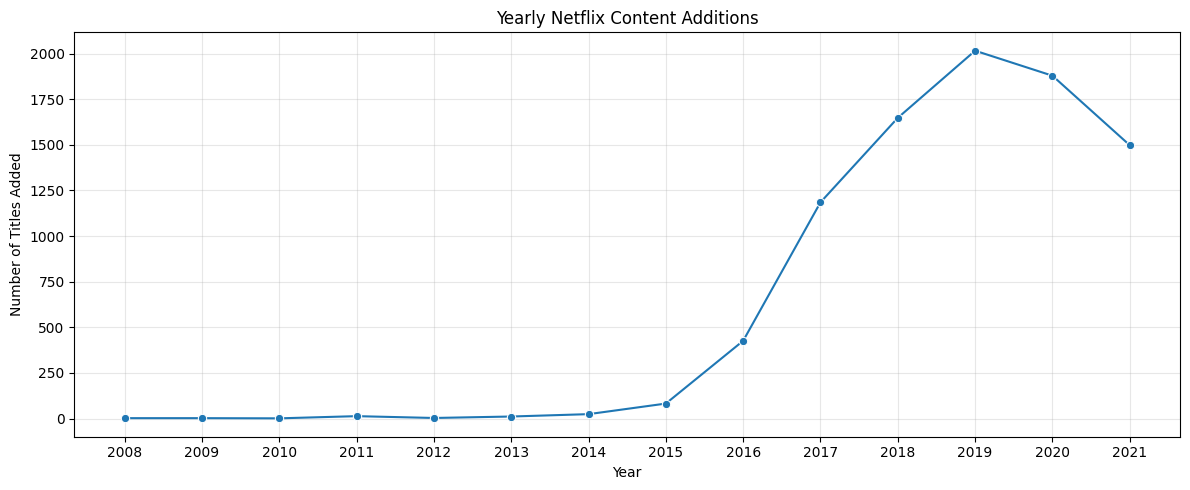

In [25]:
# Visualize the trend:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=yearly_additions,
    x="date_added_year",
    y="total_titles",
    marker="o"
)

plt.title("Yearly Netflix Content Additions")
plt.xlabel("Year")
plt.ylabel("Number of Titles Added")
plt.xticks(yearly_additions["date_added_year"])
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [26]:
# Find the peak year:
peak_year = yearly_additions.loc[
    yearly_additions["total_titles"].idxmax()
]

print("Peak Addition Year:", peak_year["date_added_year"])
print("Titles Added:", peak_year["total_titles"])

Peak Addition Year: 2019
Titles Added: 2016


Before forecasting, we need to understand the historical trend. We shouldn't build a prediction model without first examining the data.

- Additions increased rapidly from 2015 to 2019, followed by a decline in the observed data.
A useful business observation: Netflix's catalogue additions peaked in 2019 in this dataset. We should not assume the decline continued after 2021 because the dataset does not contain later observations.

### Step 4.2 — Build a trend prediction model

We'll use Linear Regression as a simple baseline forecasting model.

The idea is to learn the relationship between:
- Input (X): Year
- Target (y): Number of titles added

In [27]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

In [28]:
# Step 1: Prepare training and testing data
X = yearly_additions[["date_added_year"]]
y = yearly_additions["total_titles"]

# Chronological split
X_train = X.iloc[:-3]
X_test = X.iloc[-3:]

y_train = y.iloc[:-3]
y_test = y.iloc[-3:]

print("Training years:", X_train["date_added_year"].min(),
      "to", X_train["date_added_year"].max())

print("Testing years:", X_test["date_added_year"].tolist())

Training years: 2008 to 2018
Testing years: [2019, 2020, 2021]


In [29]:
# Train and evaluate the model
trend_model = LinearRegression()

trend_model.fit(X_train, y_train)

y_pred = trend_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))

evaluation = pd.DataFrame({
    "Year": X_test["date_added_year"].values,
    "Actual Titles": y_test.values,
    "Predicted Titles": np.round(y_pred).astype(int)
})

display(evaluation)

MAE: 572.74
RMSE: 657.78


,Year,Actual Titles,Predicted Titles
0,2019,2016,1094
1,2020,1879,1225
2,2021,1498,1356


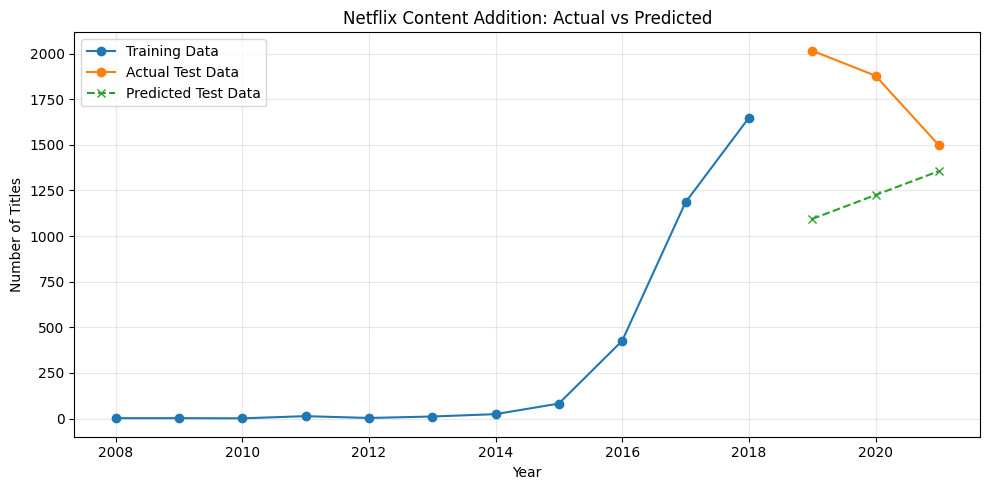

In [30]:
# Visualize actual vs predicted values
plt.figure(figsize=(10, 5))

plt.plot(
    X_train["date_added_year"], y_train,
    marker="o", label="Training Data"
)

plt.plot(
    X_test["date_added_year"], y_test,
    marker="o", label="Actual Test Data"
)

plt.plot(
    X_test["date_added_year"], y_pred,
    marker="x", linestyle="--", label="Predicted Test Data"
)

plt.title("Netflix Content Addition: Actual vs Predicted")
plt.xlabel("Year")
plt.ylabel("Number of Titles")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### Forecast the next three years

In [31]:
# Forecast the next three years
# Train on all available data
final_trend_model = LinearRegression()
final_trend_model.fit(X, y)

# Predict next three years
future_years = pd.DataFrame({
    "date_added_year": [2022, 2023, 2024]
})

future_predictions = final_trend_model.predict(future_years)

forecast_df = pd.DataFrame({
    "Year": future_years["date_added_year"],
    "Predicted Titles": np.maximum(
        0, np.round(future_predictions).astype(int)
    )
})

display(forecast_df)

# Save forecast
forecast_df.to_csv("../data/netflix_trend_forecast.csv", index=False)

,Year,Predicted Titles
0,2022,1895
1,2023,2064
2,2024,2233


Let's understand why the current model is weak:
- MAE = 572.74 titles — on average, predictions differ from actual values by about 573 titles.
- RMSE = 657.78 titles — large errors are also present.
- Linear Regression assumes a straight-line relationship, but your yearly data rises sharply and then declines.

We Use monthly aggregation and compare two models:
1. Linear Regression — baseline.
2. Random Forest Regressor — captures nonlinear patterns.

### Monthly forecasting

Convert daily dates into monthly title counts.
Fill missing months with zero.
Use the previous 1, 3, 6 and 12 months as features.
Compare Linear Regression and Random Forest.
Test on the final 12 observed months.
Forecast the next 12 months using the better model.

In [32]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
import pandas as pd
import numpy as np

# 1. Aggregate titles month-wise
monthly = (
    df_clean.groupby(df_clean["date_added"].dt.to_period("M"))
    .size()
)

# Include every month, even if no titles were added
monthly = monthly.asfreq("M", fill_value=0)
monthly.index = monthly.index.to_timestamp()

print("Monthly observations:", len(monthly))
display(monthly.tail())

# 2. Create lag features
def create_features(series):
    data = pd.DataFrame({"titles": series})

    data["lag_1"] = data["titles"].shift(1)
    data["lag_3"] = data["titles"].shift(3)
    data["lag_6"] = data["titles"].shift(6)
    data["lag_12"] = data["titles"].shift(12)
    data["rolling_mean_3"] = data["titles"].shift(1).rolling(3).mean()
    data["month"] = data.index.month
    data["time_index"] = np.arange(len(data))

    return data.dropna()

model_data = create_features(monthly)

X = model_data.drop(columns="titles")
y = model_data["titles"]

# 3. Chronological train-test split
X_train, X_test = X.iloc[:-12], X.iloc[-12:]
y_train, y_test = y.iloc[:-12], y.iloc[-12:]

# 4. Compare models
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=4,
        min_samples_leaf=2,
        random_state=42
    )
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions))
    })

results_df = pd.DataFrame(results).sort_values("MAE")
display(results_df)

# 5. Select model with lowest MAE
best_name = results_df.iloc[0]["Model"]
best_model = models[best_name]

print("Best model:", best_name)

# 6. Forecast next 12 months recursively
history = monthly.copy()
future_predictions = []

for i in range(12):
    next_date = history.index[-1] + pd.offsets.MonthBegin(1)

    row = pd.DataFrame(index=[next_date])
    row["lag_1"] = history.iloc[-1]
    row["lag_3"] = history.iloc[-3]
    row["lag_6"] = history.iloc[-6]
    row["lag_12"] = history.iloc[-12]
    row["rolling_mean_3"] = history.iloc[-3:].mean()
    row["month"] = next_date.month
    row["time_index"] = len(history)

    prediction = max(0, best_model.predict(row)[0])

    future_predictions.append({
        "Month": next_date,
        "Predicted_Titles": round(prediction)
    })

    history.loc[next_date] = prediction

forecast_monthly = pd.DataFrame(future_predictions)

display(forecast_monthly)

forecast_monthly.to_csv(
    "../data/netflix_monthly_forecast.csv",
    index=False
)

Monthly observations: 108


date_added
2021-05-01    132
2021-06-01    207
2021-07-01    257
2021-08-01    178
2021-09-01    183
dtype: int64

,Model,MAE,RMSE
1,Random Forest,34.615618,40.775817
0,Linear Regression,41.174660,42.920926


Best model: Random Forest


,Month,Predicted_Titles
0,2021-10-01,178
1,2021-11-01,184
2,2021-12-01,186
3,2022-01-01,154
4,2022-02-01,148
5,2022-03-01,150
6,2022-04-01,158
7,2022-05-01,153
8,2022-06-01,158
9,2022-07-01,156


#### Plot the monthly forecast

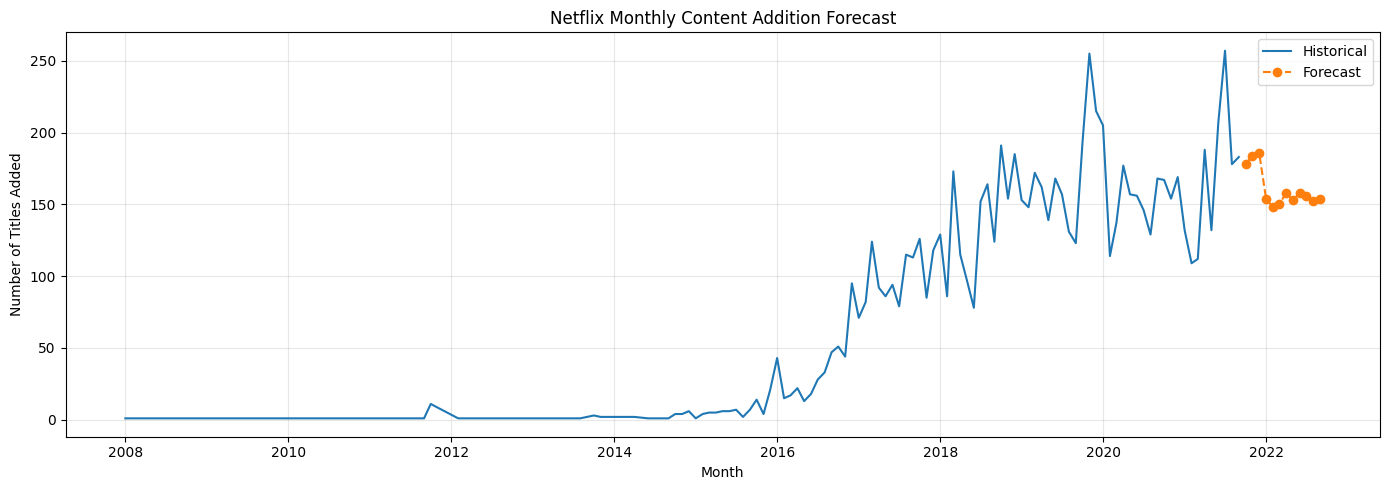

In [33]:
plt.figure(figsize=(14, 5))

plt.plot(monthly.index, monthly.values, label="Historical")
plt.plot(
    forecast_monthly["Month"],
    forecast_monthly["Predicted_Titles"],
    marker="o",
    linestyle="--",
    label="Forecast"
)

plt.title("Netflix Monthly Content Addition Forecast")
plt.xlabel("Month")
plt.ylabel("Number of Titles Added")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [34]:
# Save the selected model:
import joblib

joblib.dump(
    best_model,
    "../models/netflix_monthly_random_forest.pkl"
)

print("Monthly forecasting model saved successfully.")

Monthly forecasting model saved successfully.


In [35]:
# save the evaluation:
results_df.to_csv(
    "../reports/monthly_model_comparison.csv",
    index=False
)

### Task 4 conclusion for your report

Monthly trend analysis was performed by aggregating Netflix catalogue additions by month. Linear Regression and Random Forest Regression were evaluated using a chronological train-test split. Random Forest achieved the best performance, with an MAE of 34.62 and RMSE of 40.78. Lag-based features were used to capture recent historical patterns. The selected model was subsequently used to generate exploratory forecasts for the following 12 months.

## We can implement ARIMA and SARIMA using  existing monthly dataset.

#### compare ARIMA and SARIMA against your Random Forest model.

In [36]:
import statsmodels
print("Statsmodels:", statsmodels.__version__)

Statsmodels: 0.14.5


#### Train ARIMA and SARIMA

In [37]:
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Monthly time series
train = monthly.iloc[:-12]
test = monthly.iloc[-12:]

# ARIMA
arima_model = ARIMA(
    train,
    order=(1, 1, 1)
).fit()

arima_pred = arima_model.forecast(steps=12)

# SARIMA: yearly seasonality (12 months)
sarima_model = SARIMAX(
    train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

sarima_pred = sarima_model.forecast(steps=12)

# Evaluate
def evaluate_model(name, actual, predicted):
    return {
        "Model": name,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted))
    }

comparison = pd.DataFrame([
    evaluate_model("ARIMA", test, arima_pred),
    evaluate_model("SARIMA", test, sarima_pred)
])

display(comparison.round(2))

C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
C:\P

,Model,MAE,RMSE
0,ARIMA,33.03,41.47
1,SARIMA,38.43,46.24


#### Compare all models

In [38]:
all_results = pd.concat([
    results_df,
    comparison
], ignore_index=True)

display(
    all_results.sort_values("MAE").round(2)
)

,Model,MAE,RMSE
2,ARIMA,33.03,41.47
0,Random Forest,34.62,40.78
3,SARIMA,38.43,46.24
1,Linear Regression,41.17,42.92


#### Save the ARIMA model

In [39]:
import joblib

joblib.dump(
    arima_model,
    "../models/netflix_arima_model.pkl"
)

print("ARIMA model saved successfully.")

ARIMA model saved successfully.


In [40]:
# Save the final comparison:
all_results.to_csv(
    "../reports/forecast_model_comparison.csv",
    index=False
)

#### Generate ARIMA's next 12-month forecast

In [41]:
final_arima = ARIMA(
    monthly,
    order=(1, 1, 1)
).fit()

arima_forecast = final_arima.forecast(steps=12)

arima_forecast_df = pd.DataFrame({
    "Month": pd.date_range(
        start=monthly.index[-1] + pd.offsets.MonthBegin(1),
        periods=12,
        freq="MS"
    ),
    "Predicted_Titles": np.maximum(
        0, np.round(arima_forecast).astype(int)
    )
})

display(arima_forecast_df)

arima_forecast_df.to_csv(
    "../data/netflix_arima_forecast.csv",
    index=False
)

C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
C:\P

,Month,Predicted_Titles
108,2021-10-01,184
109,2021-11-01,184
110,2021-12-01,184
111,2022-01-01,184
112,2022-02-01,184
113,2022-03-01,184
114,2022-04-01,184
115,2022-05-01,184
116,2022-06-01,184
117,2022-07-01,184


# Task 5 — Machine Learning Classification

#### Our objective is to build a model that predicts whether a Netflix title is a Movie or TV Show using its available metadata.

We'll compare:
1. Logistic Regression
2. Random Forest Classifier

### Step 5.1 — Define the target and features

Target variable (y): type

Input features (X):
- release_year
- date_added_year
- date_added_month
- rating
- country
- listed_in

We will exclude:
- duration and duration_unit: they directly reveal whether something is a Movie or TV Show.
- title and show_id: identifiers, not useful general predictive features.
- director: very high cardinality, which can encourage memorization.

In [42]:
# Select features
features = [
    "release_year",
    "date_added_year",
    "date_added_month",
    "rating",
    "country",
    "listed_in"
]

X = df_clean[features].copy()
y = df_clean["type"].copy()

print("Feature shape:", X.shape)
print("\nTarget distribution:")
print(y.value_counts())

Feature shape: (8790, 6)

Target distribution:
type
Movie      6126
TV Show    2664
Name: count, dtype: int64


### Step 5.2 — Preprocessing and train-test split

In [43]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

numeric_features = [
    "release_year",
    "date_added_year",
    "date_added_month"
]

categorical_features = [
    "rating",
    "country",
    "listed_in"
]

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (7032, 6)
Testing shape: (1758, 6)


### Step 5.3 — Train and compare classification models

In [44]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        min_samples_split=5,
        random_state=42,
        n_jobs=-1
    )
}

classification_results = []

trained_models = {}

for name, classifier in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    trained_models[name] = pipeline

    classification_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, pos_label="Movie"
        ),
        "Recall": recall_score(
            y_test, predictions, pos_label="Movie"
        ),
        "F1 Score": f1_score(
            y_test, predictions, pos_label="Movie"
        )
    })

classification_results_df = pd.DataFrame(
    classification_results
).sort_values("F1 Score", ascending=False)

display(classification_results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.9909,0.9911,0.9959,0.9935
1,Random Forest,0.8430,0.8182,0.9959,0.8984


### Step 5.4 — Evaluate the best model

Best Model: Logistic Regression

Classification Report:
              precision    recall  f1-score   support

       Movie       0.99      1.00      0.99      1225
     TV Show       0.99      0.98      0.98       533

    accuracy                           0.99      1758
   macro avg       0.99      0.99      0.99      1758
weighted avg       0.99      0.99      0.99      1758



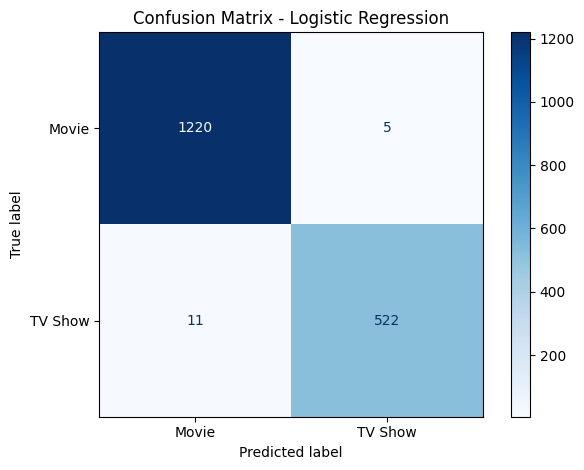

In [45]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

best_classification_name = classification_results_df.iloc[0]["Model"]
best_classification_model = trained_models[best_classification_name]

best_predictions = best_classification_model.predict(X_test)

print("Best Model:", best_classification_name)

print("\nClassification Report:")
print(classification_report(y_test, best_predictions))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_predictions,
    cmap="Blues"
)

plt.title(f"Confusion Matrix - {best_classification_name}")
plt.tight_layout()
plt.show()

#### Save your final classification model

In [46]:
import joblib

# Save the complete pipeline, including preprocessing
joblib.dump(
    best_classification_model,
    "../models/netflix_type_classifier.pkl"
)

# Save model comparison results
classification_results_df.to_csv(
    "../reports/classification_model_comparison.csv",
    index=False
)

print("Classification model and results saved successfully.")

Classification model and results saved successfully.


### Task 5 conclusion for your report

A supervised machine learning classification task was performed to predict whether a Netflix title is a Movie or TV Show. Logistic Regression and Random Forest were evaluated using a stratified train-test split. Logistic Regression achieved 99.09% accuracy and an F1-score of 99.35% for the Movie class, outperforming Random Forest. The trained Logistic Regression pipeline was selected as the final classification model.

# Task 6 — Business Insights Dashboard

# Build the Netflix dashboard